# Orca Call Detector — Training Notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR-USERNAME/orca-call-detector/blob/main/notebooks/Orca_Call_Detector.ipynb)

Data: [Orcasound](https://www.orcasound.net) Pod.Cast labeled recordings, CC BY-NC-SA 4.0.

## 1. Setup

In [1]:
!pip install -q awscli librosa

import os, json, random, base64, subprocess, tarfile
import numpy as np
import pandas as pd
import librosa, librosa.display
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
from google.colab import files

random.seed(0); np.random.seed(0); tf.random.set_seed(0)

## 2. Download the data

Orcasound's labeled recordings are public on AWS. Round 2 is from July 5, 2019 and Round 3 is from September 27, 2017, both at Orcasound Lab.

In [2]:
!aws s3 ls --no-sign-request s3://acoustic-sandbox/labeled-data/detection/train/

2019-09-26 18:38:23          0 
2019-11-18 04:57:42  258821972 OrcasoundLab07052019_PodCastRound2.tar.gz
2020-04-02 04:15:54  417794549 OrcasoundLab09272017_PodCastRound3.tar.gz
2020-10-25 07:25:38 1075749718 TestDataLatest_PodCastAllRounds_123.tar.gz
2020-09-12 07:01:40 2134169900 TrainDataLatest_PodCastAllRounds.tar.gz
2020-09-20 22:03:50 3501009623 TrainDataLatest_PodCastAllRounds_123567.tar.gz
2020-10-25 07:25:38 5461870195 TrainDataLatest_PodCastAllRounds_123567910.tar.gz
2019-11-18 05:00:17 1731393480 WHOIS09222019_PodCastRound1.tar.gz
2020-08-22 10:06:44      41904 podcast2.tsv
2020-08-22 10:07:20      57755 podcast3.tsv
2020-08-22 10:08:15      12970 test.tsv


In [3]:
def load_round(archive):
    dest = archive.replace(".tar.gz", "")
    if not os.path.exists(archive):
        subprocess.run(["aws", "s3", "cp", "--no-sign-request",
                        f"s3://acoustic-sandbox/labeled-data/detection/train/{archive}", "."], check=True)
    if not os.path.exists(dest):
        os.makedirs(dest)
        with tarfile.open(archive) as t:
            t.extractall(dest)
    return dest

R2 = load_round("OrcasoundLab07052019_PodCastRound2.tar.gz")
R3 = load_round("OrcasoundLab09272017_PodCastRound3.tar.gz")
print(R2, os.listdir(R2))
print(R3, os.listdir(R3))

OrcasoundLab07052019_PodCastRound2 ['Round2_OS_07_05']
OrcasoundLab09272017_PodCastRound3 ['Round3_OS_09_27_2017']


## 3. Round 2 labels

Each row marks one orca call: the file, when it starts, and how long it lasts. Only calls are labeled, so everything else counts as "no call." Orcasound split Round 2 into train and dev by recording.

In [4]:
BASE = os.path.join(R2, "Round2_OS_07_05")
WAV_DIR = os.path.join(BASE, "wav")
tr = pd.read_csv(os.path.join(BASE, "train.tsv"), sep="\t")
dv = pd.read_csv(os.path.join(BASE, "dev.tsv"), sep="\t")

print(open(os.path.join(BASE, "README.md")).read())
print("train rows:", tr.shape, "| dev rows:", dv.shape)
print("recordings — train:", tr["wav_filename"].nunique(), "| dev:", dv["wav_filename"].nunique())
print("recordings in both:", len(set(tr["wav_filename"]) & set(dv["wav_filename"])))
display(tr.head())

# Dataset format:

Standard dataset format understood by the `AudioFileDataset` class consists of:
* A train/dev TSV file containing at minimum, columns: `(wav_filename, start_time_s, duration_s)`
* A directory containing all the wav files pointed to by `wav_filename` 
* Precomputed mean, invstd .txt files for 64dim mel filterbank features used by the current classifier version on Pod.Cast (see src.params for details)

The TSV file only contains entries for the positive segments in a given `wav_filename`. All the remaining segments in each `wav_filename` are automatically split up into windows assumed as negative by the `AudioFileDataset` class. 
* If you think there's not enough recall in the labels for a wav file, better to chop up and keep only the positive segments as separate wav files. 
* For wavfiles containing only negative examples, the TSV has a single entry of tiny duration (0/0.01s). `AudioFileDataset` will automatically ignore this as it's too small and process the rest of

,wav_filename,start_time_s,duration_s,location,date,data_source,data_source_id
0,1562337136_0004.wav,49.765625,2.450000,orcasound_lab,2019-07-05,Orcasound_PodCast_Round2,1562337136
1,1562337136_0004.wav,41.046007,1.658854,orcasound_lab,2019-07-05,Orcasound_PodCast_Round2,1562337136
2,1562337136_0004.wav,37.345486,1.743924,orcasound_lab,2019-07-05,Orcasound_PodCast_Round2,1562337136
3,1562337136_0004.wav,42.917535,2.594618,orcasound_lab,2019-07-05,Orcasound_PodCast_Round2,1562337136
4,1562337136_0004.wav,45.980035,2.041667,orcasound_lab,2019-07-05,Orcasound_PodCast_Round2,1562337136


## 4. Turn audio into spectrogram windows

Each recording is cut into 2.45-second windows, one second apart. A window is a **call** if it overlaps a labeled call by at least 0.4 s, **no call** if it overlaps none, and is skipped otherwise. Each window becomes a 64 × 77 mel spectrogram.

In [5]:
SR, WIN_S, HOP_S, MIN_OVL = 16000, 2.45, 1.0, 0.4
TARGET_FRAMES = 77

def melspec(y, sr=SR, n_mels=64):
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=1024, hop_length=512,
                                       n_mels=n_mels, fmin=50, fmax=8000)
    return librosa.power_to_db(S, ref=1.0)

def overlap(a0, a1, b0, b1):
    return max(0.0, min(a1, b1) - max(a0, b0))

def build(df, wav_dir):
    calls = {fn: [(r.start_time_s, r.start_time_s + r.duration_s)
                  for r in g.itertuples() if r.duration_s > 0]
             for fn, g in df.groupby("wav_filename")}
    files_ = [f for f in sorted(calls) if os.path.exists(os.path.join(wav_dir, f))]

    X, y, src = [], [], []
    for fn in files_:
        audio, _ = librosa.load(os.path.join(wav_dir, fn), sr=SR)
        dur, ivs = len(audio) / SR, calls[fn]
        t = 0.0
        while t + WIN_S <= dur:
            ov = max([overlap(t, t + WIN_S, c0, c1) for c0, c1 in ivs], default=0.0)
            if   ov >= MIN_OVL: label = 1
            elif ov == 0.0:     label = 0
            else:               t += HOP_S; continue
            S = melspec(audio[int(t*SR):int((t+WIN_S)*SR)])
            if S.shape[1] < TARGET_FRAMES:
                S = np.pad(S, ((0,0),(0,TARGET_FRAMES-S.shape[1])), constant_values=S.min())
            X.append(S[:, :TARGET_FRAMES]); y.append(label); src.append(fn)
            t += HOP_S
    return np.array(X, np.float32), np.array(y, np.float32), np.array(src)

In [7]:
X_tr_r2_raw, y_tr_r2_raw, src_tr_r2 = build(tr, WAV_DIR)
X_va_r2_raw, y_va_r2, src_va_r2 = build(dv, WAV_DIR)

print("Round 2 train:", X_tr_r2_raw.shape, "calls:", int(y_tr_r2_raw.sum()), "no call:", int((y_tr_r2_raw == 0).sum()))
print("Round 2 dev:  ", X_va_r2_raw.shape, "calls:", int(y_va_r2.sum()), "no call:", int((y_va_r2 == 0).sum()))

Round 2 train: (2845, 64, 77) calls: 1101 no call: 1744
Round 2 dev:   (388, 64, 77) calls: 215 no call: 173


## 5. Add Round 3

Round 3 has no ready-made split, so the last 15% of its recordings (in time order) are held out as one block. Recordings next to each other in time share the same whales and background noise, so a random split would make scores look better than they are.

Round 2's dev set stays the fixed benchmark for every comparison.

In [8]:
BASE3 = os.path.join(R3, "Round3_OS_09_27_2017")
WAV3 = os.path.join(BASE3, "wav")
labels3 = pd.read_csv(os.path.join(BASE3, "train.tsv"), sep="\t")

names3 = sorted(labels3["wav_filename"].unique())
held3 = set(names3[-max(1, round(0.15 * len(names3))):])
X3_tr, y3_tr, s3_tr = build(labels3[~labels3["wav_filename"].isin(held3)], WAV3)
print(f"Round 3: {len(names3) - len(held3)} training recordings, {len(held3)} held out")

data_r2   = (X_tr_r2_raw, y_tr_r2_raw)
data_r2r3 = (np.concatenate([X_tr_r2_raw, X3_tr]), np.concatenate([y_tr_r2_raw, y3_tr]))
print("Round 2 only:", data_r2[0].shape, "| Rounds 2 + 3:", data_r2r3[0].shape)

Round 3: 78 training recordings, 14 held out
Round 2 only: (2845, 64, 77) | Rounds 2 + 3: (7313, 64, 77)


## 6. Look at the data

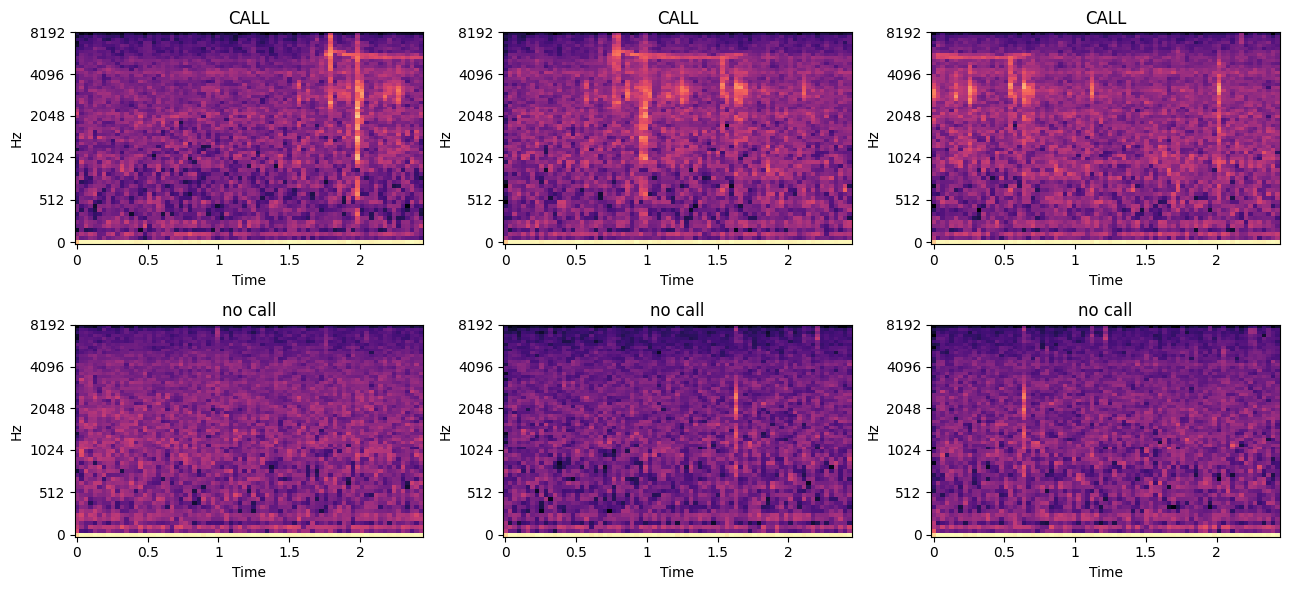

In [9]:
Xv, yv = data_r2r3
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, i in zip(axes[0], np.where(yv == 1)[0][:3]):
    librosa.display.specshow(Xv[i], sr=SR, hop_length=512, x_axis="time", y_axis="mel", ax=ax); ax.set_title("CALL")
for ax, i in zip(axes[1], np.where(yv == 0)[0][:3]):
    librosa.display.specshow(Xv[i], sr=SR, hop_length=512, x_axis="time", y_axis="mel", ax=ax); ax.set_title("no call")
plt.tight_layout(); plt.show()

## 7. Normalize

Each frequency band is scaled using the mean and standard deviation of the training data. Version 0.1 scaled every window to its own loudest point instead, which erased how loud sounds really were, and the model couldn't learn.

In [10]:
mean = data_r2r3[0].mean(axis=(0, 2))
std  = data_r2r3[0].std(axis=(0, 2)) + 1e-6

def prep(a):
    return ((a - mean[None, :, None]) / std[None, :, None])[..., np.newaxis]

## 8. The model

Three convolutional layers, the last layer outputs the probability of a call.

In [11]:
def build_model():
    m = keras.Sequential([
        layers.Input(shape=(64, TARGET_FRAMES, 1)),
        layers.Conv2D(16, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 77, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 38, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 38, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 19, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 19, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 9, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,521 (107.50 KB)

 Trainable params: 27,521 (107.50 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Experiment: does more data help?

Trains the same model three times (different random seeds) on Round 2 only, and three times on Rounds 2 + 3, scoring each on the Round 2 benchmark. One run can be lucky or unlucky, so the averages are what count.

In [11]:
LR = 1e-3

def run_experiment(data, seed):
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    Xtr_raw, ytr = data
    m_ = Xtr_raw.mean(axis=(0, 2)); s_ = Xtr_raw.std(axis=(0, 2)) + 1e-6
    pp = lambda a: ((a - m_[None, :, None]) / s_[None, :, None])[..., np.newaxis]
    net = keras.models.clone_model(model)
    net.compile(optimizer=keras.optimizers.Adam(LR), loss="binary_crossentropy",
                metrics=[keras.metrics.AUC(name="auc")])
    stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                         patience=6, restore_best_weights=True)
    net.fit(pp(Xtr_raw), ytr, validation_data=(pp(X_va_r2_raw), y_va_r2),
            epochs=40, batch_size=32, callbacks=[stop], verbose=0)
    auc = roc_auc_score(y_va_r2, net.predict(pp(X_va_r2_raw), verbose=0).ravel())
    return auc, net, (m_, s_)

results = {}
for name, data in (("Round 2 only", data_r2), ("Rounds 2 + 3", data_r2r3)):
    runs = [run_experiment(data, seed) for seed in (0, 1, 2)]
    results[name] = runs
    aucs = [r[0] for r in runs]
    print(f"{name}: " + ", ".join(f"{a:.3f}" for a in aucs) + f"  | average {np.mean(aucs):.3f}")

KeyboardInterrupt: 

## 10. Final model

Uses the best Rounds 2 + 3 run. If the experiment wasn't re-run, it loads the saved copy — upload `orca_detector.keras` to Colab's file panel first.

In [15]:
if "results" in globals():
    best_auc, model, (mean, std) = max(results["Rounds 2 + 3"], key=lambda r: r[0])
else:
    model = keras.models.load_model("orca_detector (2).keras")

X_tr, y_tr = prep(data_r2r3[0]), data_r2r3[1]
X_va, y_va = prep(X_va_r2_raw), y_va_r2
p = model.predict(X_va, verbose=0).ravel()
print("Round 2 benchmark AUC:", round(roc_auc_score(y_va, p), 3))

Round 2 benchmark AUC: 0.881


## 11. Choose the detection threshold

A lower threshold finds more calls but raises more false alarms.

In [16]:
for t in (0.5, 0.4, 0.3, 0.2, 0.1):
    c = confusion_matrix(y_va, (p >= t).astype(int))
    print(f"threshold {t:.1f}: recall {c[1][1]/c[1].sum():.2f}, "
          f"precision {c[1][1]/max(1, c[0][1]+c[1][1]):.2f}, false alarms {c[0][1]}")

threshold 0.5: recall 0.63, precision 0.96, false alarms 5
threshold 0.4: recall 0.69, precision 0.93, false alarms 12
threshold 0.3: recall 0.80, precision 0.85, false alarms 29
threshold 0.2: recall 0.88, precision 0.74, false alarms 65
threshold 0.1: recall 0.99, precision 0.57, false alarms 162


In [17]:
THRESHOLD = 0.20

pred = (p >= THRESHOLD).astype(int)
cm = confusion_matrix(y_va, pred)
print("Confusion matrix  [rows: true, cols: predicted]")
print("            no call  call")
print("no call    ", cm[0])
print("call       ", cm[1])
print()
print(classification_report(y_va, pred, target_names=["no call", "call"]))
print("AUC:", round(roc_auc_score(y_va, p), 3),
      "| recall:", round(cm[1][1] / cm[1].sum(), 3),
      "| precision:", round(cm[1][1] / (cm[0][1] + cm[1][1]), 3))

Confusion matrix  [rows: true, cols: predicted]
            no call  call
no call     [108  65]
call        [ 26 189]

              precision    recall  f1-score   support

     no call       0.81      0.62      0.70       173
        call       0.74      0.88      0.81       215

    accuracy                           0.77       388
   macro avg       0.78      0.75      0.75       388
weighted avg       0.77      0.77      0.76       388

AUC: 0.881 | recall: 0.879 | precision: 0.744


## 12. Export for the website

Saves the model, then writes `model_web.json` with the architecture, the trained weights, and the preprocessing settings, so the website processes audio exactly like this notebook. It checks the settings against `melspec()` and `prep()` before saving.

In [18]:
VERSION = "v0.3.0"
TRAINED_ON = "Orcasound Pod.Cast Rounds 2 and 3 — Orcasound Lab, July 5, 2019 and September 27, 2017"

model.save("orca_detector.keras")

wav0 = sorted(f for f in os.listdir(WAV_DIR) if f.endswith(".wav"))[0]
seg, _ = librosa.load(os.path.join(WAV_DIR, wav0), sr=SR, duration=WIN_S)
S_check = melspec(seg)

def spec_with(ref):
    S = librosa.feature.melspectrogram(y=seg, sr=SR, n_fft=1024, hop_length=512, n_mels=64, fmin=50, fmax=8000)
    return librosa.power_to_db(S, ref=np.max if ref == "max" else ref)

db_ref = next((r for r in ("max", 1.0) if np.allclose(spec_with(r), S_check, atol=1e-3)), None)
assert db_ref is not None, "melspec() settings not recognized"
norm = {"type": "mean_invstd", "mean": mean.tolist(), "invstd": (1 / std).tolist()}
assert np.allclose((S_check - mean[:, None]) / std[:, None], prep(S_check[None])[0, ..., 0], atol=1e-4), "prep() not recognized"

SUPPORTED = {"InputLayer", "Conv2D", "MaxPooling2D", "GlobalAveragePooling2D", "GlobalMaxPooling2D",
             "Dropout", "Dense", "BatchNormalization", "Activation", "Flatten"}
KEYS = ("activation", "padding", "strides", "pool_size", "epsilon", "center", "scale", "kernel_size", "use_bias")
layers_out = []
for layer in model.layers:
    kind = layer.__class__.__name__
    assert kind in SUPPORTED, f"{kind} layers aren't supported by the website"
    if kind == "InputLayer":
        continue
    cfg = layer.get_config()
    layers_out.append({"type": kind, "config": {k: cfg[k] for k in KEYS if k in cfg},
                       "weights": [{"shape": list(w.shape),
                                    "b64": base64.b64encode(np.asarray(w, dtype="<f4").tobytes()).decode()}
                                   for w in layer.get_weights()]})

doc = {
    "format": "orca-web-v1",
    "input_shape": list(model.input_shape[1:]),
    "preprocessing": {"sr": SR, "win_s": WIN_S, "hop_s": HOP_S, "n_fft": 1024, "hop_length": 512,
                      "n_mels": 64, "fmin": 50, "fmax": 8000, "target_frames": TARGET_FRAMES,
                      "db_ref": db_ref, "norm": norm},
    "meta": {"version": VERSION, "threshold": THRESHOLD,
             "auc": round(float(roc_auc_score(y_va, p)), 3),
             "recall": round(float(cm[1][1] / cm[1].sum()), 3),
             "precision": round(float(cm[1][1] / max(1, cm[0][1] + cm[1][1])), 3),
             "train_windows": int(len(X_tr)), "dev_windows": int(len(X_va)),
             "params": int(model.count_params()), "trained_on": TRAINED_ON},
    "layers": layers_out,
}
with open("model_web.json", "w") as f:
    json.dump(doc, f)
print(f"Saved model_web.json ({os.path.getsize('model_web.json') // 1024} KB), {VERSION}, db_ref={db_ref}")
files.download("model_web.json")

Saved model_web.json (147 KB), v0.3.0, db_ref=1.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>